
# StyleSense – H&M Fashion Intelligence
## Simple, step-by-step Machine Learning Project

1. Hybrid Fashion Recommendation System
2. Low-Sales Risk Prediction

The transaction file is large, so it is read in chunks. We keep the 90-day history and following 30-day evaluation period in memory.

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import gc
import joblib

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix, save_npz

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Set the folder path

In [ ]:
DATA_FOLDER = "/content/drive/MyDrive/Style_Sense_mlproj"

ARTICLES_FILE = DATA_FOLDER + "/articles.csv"
CUSTOMERS_FILE = DATA_FOLDER + "/customers.csv"
TRANSACTIONS_FILE = DATA_FOLDER + "/transactions_train.csv"

print(os.listdir(DATA_FOLDER))

['articles.csv', 'customers.csv', 'transactions_train.csv', 'StyleSense_Artifacts']


## 3. Load articles and check customers

In [ ]:
articles = pd.read_csv(ARTICLES_FILE)

print("Articles shape:", articles.shape)
display(articles.head())
print(articles.dtypes)
print("Missing values:")
print(articles.isnull().sum())
print("Duplicate article IDs:", articles["article_id"].duplicated().sum())

# Count customers without loading the whole customer file
customer_count = 0
for part in pd.read_csv(CUSTOMERS_FILE, usecols=["customer_id"], chunksize=200000):
    customer_count += len(part)

print("Total customer records:", customer_count)

Articles shape: (105542, 25)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


article_id                       int64
product_code                     int64
prod_name                       object
product_type_no                  int64
product_type_name               object
product_group_name              object
graphical_appearance_no          int64
graphical_appearance_name       object
colour_group_code                int64
colour_group_name               object
perceived_colour_value_id        int64
perceived_colour_value_name     object
perceived_colour_master_id       int64
perceived_colour_master_name    object
department_no                    int64
department_name                 object
index_code                      object
index_name                      object
index_group_no                   int64
index_group_name                object
section_no                       int64
section_name                    object
garment_group_no                 int64
garment_group_name              object
detail_desc                     object
dtype: object
Missing val

## 4. Read the large transaction file safely

In [ ]:
# First find the latest transaction date
latest_date = pd.Timestamp.min

for part in pd.read_csv(TRANSACTIONS_FILE, usecols=["t_dat"], chunksize=1000000):
    part["t_dat"] = pd.to_datetime(part["t_dat"])
    if part["t_dat"].max() > latest_date:
        latest_date = part["t_dat"].max()

print("Latest date:", latest_date)

Latest date: 2020-09-22 00:00:00


In [ ]:
# Define 90-day history and 30-day future test period
test_start = latest_date - pd.Timedelta(days=30)
history_start = test_start - pd.Timedelta(days=90)

TRAIN_FILE = "/content/stylesense_history.csv"
TEST_FILE = "/content/stylesense_future.csv"

for file in [TRAIN_FILE, TEST_FILE]:
    if os.path.exists(file):
        os.remove(file)

train_written = False
test_written = False

use_cols = ["t_dat", "customer_id", "article_id", "price"]

for part in pd.read_csv(
    TRANSACTIONS_FILE,
    usecols=use_cols,
    chunksize=400000,
    dtype={"customer_id": "string", "article_id": "int32", "price": "float32"}
):
    part["t_dat"] = pd.to_datetime(part["t_dat"])

    history = part[
        (part["t_dat"] >= history_start) &
        (part["t_dat"] < test_start)
    ]
    future = part[
        (part["t_dat"] >= test_start) &
        (part["t_dat"] <= latest_date)
    ]

    if len(history) > 0:
        history.to_csv(TRAIN_FILE, mode="a", header=not train_written, index=False)
        train_written = True

    if len(future) > 0:
        future.to_csv(TEST_FILE, mode="a", header=not test_written, index=False)
        test_written = True

    del part, history, future
    gc.collect()

print("Transaction filtering completed.")

Transaction filtering completed.


In [ ]:
# Load only the selected date ranges
types = {
    "customer_id": "category",
    "article_id": "int32",
    "price": "float32"
}

train_transactions = pd.read_csv(TRAIN_FILE, dtype=types, parse_dates=["t_dat"])
test_transactions = pd.read_csv(TEST_FILE, dtype=types, parse_dates=["t_dat"])

print("History data:", train_transactions.shape)
print("Future data:", test_transactions.shape)
print("History dates:", train_transactions["t_dat"].min(), "to",
      train_transactions["t_dat"].max())
print("Future dates:", test_transactions["t_dat"].min(), "to",
      test_transactions["t_dat"].max())

History data: (4360505, 4)
Future data: (1122902, 4)
History dates: 2020-05-26 00:00:00 to 2020-08-23 00:00:00
Future dates: 2020-08-24 00:00:00 to 2020-09-22 00:00:00


## 5. Explore transaction data

In [ ]:
display(train_transactions.head())
print(train_transactions.shape)
print(train_transactions.dtypes)
print(train_transactions.isnull().sum())
print("Duplicate rows:", train_transactions.duplicated().sum())
display(train_transactions.describe())

,t_dat,customer_id,article_id,price
0,2020-05-26,0000f2ea26b7f0a9175f428c8cf7743e9e10e193465ecd...,858640004,0.050831
1,2020-05-26,0000f2ea26b7f0a9175f428c8cf7743e9e10e193465ecd...,808840004,0.025407
2,2020-05-26,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,855198004,0.022017
3,2020-05-26,0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37...,857277001,0.033881
4,2020-05-26,00052ddcff0fb9e557eb3b212c950a24dc3900c28bb705...,861519001,0.068627


(4360505, 4)
t_dat          datetime64[ns]
customer_id          category
article_id              int32
price                 float32
dtype: object
t_dat          0
customer_id    0
article_id     0
price          0
dtype: int64
Duplicate rows: 355740


,t_dat,article_id,price
count,4360505,4.360505e+06,4.360505e+06
mean,2020-07-06 00:56:16.045664256,7.816669e+08,2.461601e-02
min,2020-05-26 00:00:00,1.087750e+08,3.389830e-05
25%,2020-06-17 00:00:00,7.371370e+08,1.500000e-02
50%,2020-07-02 00:00:00,8.222030e+08,2.201695e-02
75%,2020-07-28 00:00:00,8.620540e+08,3.049153e-02
max,2020-08-23 00:00:00,9.495510e+08,5.067797e-01
std,NaN,1.240547e+08,1.528595e-02


## 6. Clean the product catalogue

In [ ]:
# Exclude intimate apparel, nightwear and swimwear product types
exclude_groups = ["Underwear", "Underwear/nightwear", "Nightwear"]
exclude_types = [
    "Bra", "Bra extender", "Bikini top", "Pyjama set",
    "Pyjama bottom", "Night gown", "Robe", "Swimwear bottom",
    "Swimwear top", "Swimwear set", "Swimsuit"
]

articles_clean = articles[
    ~articles["product_group_name"].isin(exclude_groups) &
    ~articles["product_type_name"].isin(exclude_types)
].copy()

print("Original articles:", articles.shape)
print("After cleaning:", articles_clean.shape)
display(articles_clean["product_group_name"].value_counts().head(15))

Original articles: (105542, 25)
After cleaning: (95038, 25)


,count
product_group_name,
Garment Upper body,42741
Garment Lower body,19812
Garment Full body,13292
Accessories,11158
Shoes,5283
Socks & Tights,2442
Unknown,121
Swimwear,66
Cosmetic,49


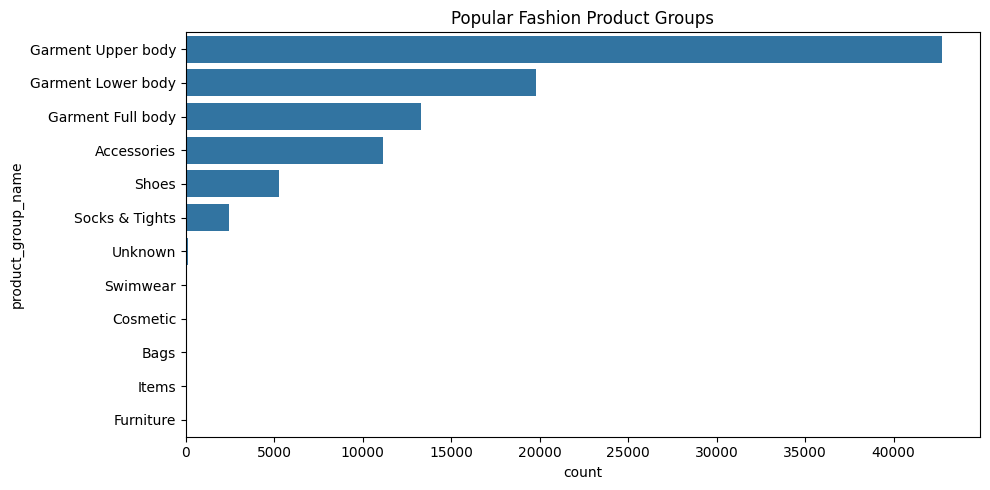

In [ ]:
# Visualise popular product groups
plt.figure(figsize=(10, 5))
sns.countplot(
    data=articles_clean,
    y="product_group_name",
    order=articles_clean["product_group_name"].value_counts().head(12).index
)
plt.title("Popular Fashion Product Groups")
plt.tight_layout()
plt.show()

## 7. Outlier detection (IQR method)

The IQR method flags values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR. These are only *possible* outliers. We inspect them before deciding what to do. Genuine high-price products and frequent customers should not be removed automatically.

In [ ]:
# Check possible outliers in transaction price
Q1 = train_transactions["price"].quantile(0.25)
Q3 = train_transactions["price"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

price_outliers = train_transactions[
    (train_transactions["price"] < lower_limit) |
    (train_transactions["price"] > upper_limit)
]

print("Price lower limit:", lower_limit)
print("Price upper limit:", upper_limit)
print("Possible price outliers:", len(price_outliers))
print("Percentage:", round(len(price_outliers) / len(train_transactions) * 100, 2), "%")
print("Negative prices:", (train_transactions["price"] < 0).sum())
display(train_transactions["price"].describe())

Price lower limit: -0.008237288799136877
Price upper limit: 0.05372881377115846
Possible price outliers: 172011
Percentage: 3.94 %
Negative prices: 0


,price
count,4.360505e+06
mean,2.461601e-02
std,1.528595e-02
min,3.389830e-05
25%,1.500000e-02
50%,2.201695e-02
75%,3.049153e-02
max,5.067797e-01


In [ ]:
# Check possible outliers in customer purchase frequency
purchase_count = train_transactions.groupby(
    "customer_id", observed=True
).size().reset_index(name="purchase_count")

Q1 = purchase_count["purchase_count"].quantile(0.25)
Q3 = purchase_count["purchase_count"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

customer_outliers = purchase_count[
    (purchase_count["purchase_count"] < lower_limit) |
    (purchase_count["purchase_count"] > upper_limit)
]

print("Possible customer outliers:", len(customer_outliers))
print("Percentage:", round(len(customer_outliers) / len(purchase_count) * 100, 2), "%")
display(purchase_count["purchase_count"].describe())

Possible customer outliers: 40700
Percentage: 7.54 %


,purchase_count
count,539884.000000
mean,8.076744
std,9.644666
min,1.000000
25%,3.000000
50%,5.000000
75%,10.000000
max,380.000000


**Decision:** Do not remove all flagged rows. First check if they are invalid. The H&M price column is scaled, and very active customers may be genuine. This notebook keeps valid observations and reports the outlier check transparently.

# Part A – Low-Sales Risk Prediction

**Goal:** Predict whether a product will have relatively low sales in the following 30 days. Low-sales risk is defined as future sales at or below the 25th percentile within its product group.

In [ ]:
# Calculate product sales in the previous 30, 60 and 90 days
sales_30 = train_transactions[
    train_transactions["t_dat"] >= test_start - pd.Timedelta(days=30)
].groupby("article_id").size().rename("sales_30d")

sales_60 = train_transactions[
    train_transactions["t_dat"] >= test_start - pd.Timedelta(days=60)
].groupby("article_id").size().rename("sales_60d")

sales_90 = train_transactions.groupby("article_id").size().rename("sales_90d")
avg_price = train_transactions.groupby("article_id")["price"].mean().rename("average_price")

product_sales = pd.concat([sales_30, sales_60, sales_90, avg_price], axis=1).fillna(0)
product_sales = product_sales.reset_index()

future_sales = test_transactions.groupby("article_id").size().rename("future_sales").reset_index()

sales_article_info = articles_clean[
    ["article_id", "product_group_name", "product_type_name", "colour_group_name"]
].drop_duplicates("article_id")
sales_data = sales_article_info.merge(product_sales, on="article_id", how="inner")
sales_data = sales_data.merge(future_sales, on="article_id", how="left")
sales_data["future_sales"] = sales_data["future_sales"].fillna(0)

display(sales_data.head())

,article_id,product_group_name,product_type_name,colour_group_name,sales_30d,sales_60d,sales_90d,average_price,future_sales
0,108775015,Garment Upper body,Vest top,Black,0.0,3.0,5,0.004742,0.0
1,108775044,Garment Upper body,Vest top,White,20.0,62.0,153,0.007896,18.0
2,111565001,Socks & Tights,Underwear Tights,Black,70.0,209.0,314,0.005581,124.0
3,111586001,Garment Lower body,Leggings/Tights,Black,50.0,171.0,253,0.012193,337.0
4,111593001,Socks & Tights,Underwear Tights,Black,57.0,156.0,223,0.011468,335.0


In [ ]:
# Create low-sales target using the 25th percentile in each product group
group_limit = sales_data.groupby("product_group_name")["future_sales"].transform(
    lambda x: x.quantile(0.25)
)

sales_data["sales_risk"] = (sales_data["future_sales"] <= group_limit).astype(int)

print("Target counts:")
display(sales_data["sales_risk"].value_counts())

Target counts:


,count
sales_risk,
0,21381
1,15467


In [ ]:
# Prepare input columns and target
sales_X = sales_data[
    ["sales_30d", "sales_60d", "sales_90d", "average_price",
     "product_group_name", "product_type_name", "colour_group_name"]
].copy()

sales_y = sales_data["sales_risk"]

sales_X = pd.get_dummies(
    sales_X,
    columns=["product_group_name", "product_type_name", "colour_group_name"],
    dtype=int
)

sales_X_train, sales_X_test, sales_y_train, sales_y_test = train_test_split(
    sales_X, sales_y, test_size=0.20, random_state=42, stratify=sales_y
)

print("Train shape:", sales_X_train.shape)
print("Test shape:", sales_X_test.shape)

Train shape: (29478, 170)
Test shape: (7370, 170)


### Model 1 – Naive Bayes

In [ ]:
sales_nb = GaussianNB()
sales_nb.fit(sales_X_train, sales_y_train)
sales_nb_pred = sales_nb.predict(sales_X_test)

print("Accuracy:", accuracy_score(sales_y_test, sales_nb_pred))
print("Precision:", precision_score(sales_y_test, sales_nb_pred, zero_division=0))
print("Recall:", recall_score(sales_y_test, sales_nb_pred, zero_division=0))
print("F1:", f1_score(sales_y_test, sales_nb_pred, zero_division=0))
print(classification_report(sales_y_test, sales_nb_pred, zero_division=0))

Accuracy: 0.6645861601085482
Precision: 0.5623746490172483
Recall: 0.9062702003878474
F1: 0.694059405940594
              precision    recall  f1-score   support

           0       0.88      0.49      0.63      4276
           1       0.56      0.91      0.69      3094

    accuracy                           0.66      7370
   macro avg       0.72      0.70      0.66      7370
weighted avg       0.75      0.66      0.66      7370



### Model 2 – Random Forest

In [ ]:
sales_rf = RandomForestClassifier(
    n_estimators=150, max_depth=15, min_samples_leaf=2,
    class_weight="balanced", random_state=42, n_jobs=-1
)
sales_rf.fit(sales_X_train, sales_y_train)
sales_rf_pred = sales_rf.predict(sales_X_test)

print("Accuracy:", accuracy_score(sales_y_test, sales_rf_pred))
print("Precision:", precision_score(sales_y_test, sales_rf_pred, zero_division=0))
print("Recall:", recall_score(sales_y_test, sales_rf_pred, zero_division=0))
print("F1:", f1_score(sales_y_test, sales_rf_pred, zero_division=0))
print(classification_report(sales_y_test, sales_rf_pred, zero_division=0))

Accuracy: 0.824966078697422
Precision: 0.7550904977375565
Recall: 0.8629605688429218
F1: 0.8054298642533937
              precision    recall  f1-score   support

           0       0.89      0.80      0.84      4276
           1       0.76      0.86      0.81      3094

    accuracy                           0.82      7370
   macro avg       0.82      0.83      0.82      7370
weighted avg       0.83      0.82      0.83      7370



Decision Tree accuracy: 0.8081411126187246
              precision    recall  f1-score   support

           0       0.87      0.79      0.83      4276
           1       0.74      0.84      0.79      3094

    accuracy                           0.81      7370
   macro avg       0.80      0.81      0.81      7370
weighted avg       0.82      0.81      0.81      7370



,Model,Accuracy,Precision,Recall,F1
1,Random Forest,0.824966,0.755090,0.862961,0.805430
2,Decision Tree,0.808141,0.739863,0.837427,0.785628
0,Naive Bayes,0.664586,0.562375,0.906270,0.694059


Best Low-Sales model: Random Forest


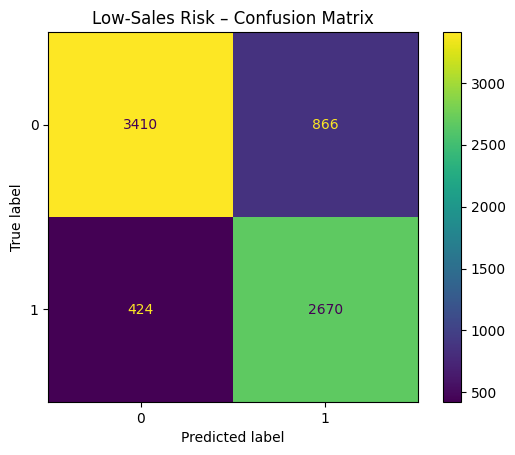

In [ ]:
# Model 3 – Decision Tree
sales_dt = DecisionTreeClassifier(
    max_depth=12, min_samples_leaf=5, class_weight="balanced",
    random_state=42
)
sales_dt.fit(sales_X_train, sales_y_train)
sales_dt_pred = sales_dt.predict(sales_X_test)

print("Decision Tree accuracy:", accuracy_score(sales_y_test, sales_dt_pred))
print(classification_report(sales_y_test, sales_dt_pred, zero_division=0))

# Compare all three Low-Sales Risk models
sales_results = pd.DataFrame({
    "Model": ["Naive Bayes", "Random Forest", "Decision Tree"],
    "Accuracy": [
        accuracy_score(sales_y_test, sales_nb_pred),
        accuracy_score(sales_y_test, sales_rf_pred),
        accuracy_score(sales_y_test, sales_dt_pred)
    ],
    "Precision": [
        precision_score(sales_y_test, sales_nb_pred, zero_division=0),
        precision_score(sales_y_test, sales_rf_pred, zero_division=0),
        precision_score(sales_y_test, sales_dt_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(sales_y_test, sales_nb_pred, zero_division=0),
        recall_score(sales_y_test, sales_rf_pred, zero_division=0),
        recall_score(sales_y_test, sales_dt_pred, zero_division=0)
    ],
    "F1": [
        f1_score(sales_y_test, sales_nb_pred, zero_division=0),
        f1_score(sales_y_test, sales_rf_pred, zero_division=0),
        f1_score(sales_y_test, sales_dt_pred, zero_division=0)
    ]
}).sort_values("F1", ascending=False)

display(sales_results)

best_sales_name = sales_results.iloc[0]["Model"]
sales_model_options = {
    "Naive Bayes": sales_nb,
    "Random Forest": sales_rf,
    "Decision Tree": sales_dt
}
best_sales_model = sales_model_options[best_sales_name]
best_sales_pred = best_sales_model.predict(sales_X_test)

print("Best Low-Sales model:", best_sales_name)
ConfusionMatrixDisplay.from_predictions(sales_y_test, best_sales_pred)
plt.title("Low-Sales Risk – Confusion Matrix")
plt.show()

# Part B – Hybrid Fashion Recommendation System


- **Popularity-based:** recommends frequently purchased products.
- **Collaborative filtering:** finds customers with similar purchase histories using cosine similarity and KNN.
- **Hybrid ranking:** combines popularity and collaborative scores.

The collaborative model uses a sparse customer-product matrix and the 10,000 most active customers to manage memory.

In [ ]:
# Find the 10,000 most active customers
active_customer_counts = train_transactions["customer_id"].value_counts()
selected_customers = active_customer_counts.head(10000).index

cf_transactions = train_transactions[
    train_transactions["customer_id"].isin(selected_customers)
][["customer_id", "article_id"]].drop_duplicates()

print("Customers selected:", cf_transactions["customer_id"].nunique())
print("Interactions:", len(cf_transactions))

Customers selected: 10000
Interactions: 428209


In [ ]:
# Create sparse customer-product matrix
customer_codes, customer_ids = pd.factorize(cf_transactions["customer_id"])
product_codes, product_ids = pd.factorize(cf_transactions["article_id"])

interaction_matrix = csr_matrix(
    (np.ones(len(cf_transactions), dtype=np.float32),
     (customer_codes, product_codes)),
    shape=(len(customer_ids), len(product_ids))
)

print("Matrix shape:", interaction_matrix.shape)
print("Non-zero values:", interaction_matrix.nnz)

Matrix shape: (10000, 28438)
Non-zero values: 428209


In [ ]:
# Fit KNN model using cosine distance
knn_model = NearestNeighbors(
    n_neighbors=6, metric="cosine", algorithm="brute", n_jobs=1
)
knn_model.fit(interaction_matrix)

# Find five similar customers for one example customer
distances, indices = knn_model.kneighbors(interaction_matrix[0])

print("Selected customer:", customer_ids[0])
for i in range(1, 6):
    print("Similar customer:", customer_ids[indices[0][i]],
          "Similarity:", round(1 - distances[0][i], 3))

Selected customer: 0001d44dbe7f6c4b35200abdb052c77a87596fe1bdcc37e011580a479e80aa94
Similar customer: fc33aba87c528d29fe3813217a327a5b6d7704445ae0f288f8d98623d8f6fe9a Similarity: 0.123
Similar customer: 897cd84a6711508a8c73766efd37e48e45d7bda0d2c9aa7cfdb9b12b740b126f Similarity: 0.096
Similar customer: 41541351b0be2cf8dcfae07eafeda090d10315736272ecd241b84abaf30250b2 Similarity: 0.095
Similar customer: 333bfd85c344eda248d8745fe408cc8e44c20f1bff49bca6122d0391eb58f018 Similarity: 0.086
Similar customer: e2e398ce5bd2eb4e4a60611dc33b04abd5196200cc39e6f9f52f1ea2b2d1e620 Similarity: 0.086


In [ ]:
# Popular products from the training period
product_popularity = train_transactions["article_id"].value_counts()
popular_products = product_popularity.head(10).index

popular_table = pd.DataFrame({"article_id": popular_products})
popular_table = popular_table.merge(
    articles_clean[["article_id", "prod_name", "product_type_name",
                    "product_group_name", "colour_group_name"]],
    on="article_id", how="left"
)
display(popular_table)

,article_id,prod_name,product_type_name,product_group_name,colour_group_name
0,599580038,NaN,NaN,NaN,NaN
1,372860002,7p Basic Shaftless,Socks,Socks & Tights,White
2,759871002,Tilda tank,Vest top,Garment Upper body,Black
3,706016001,Jade HW Skinny Denim TRS,Trousers,Garment Lower body,Black
4,817472002,Kelso,Shorts,Garment Lower body,Light Beige
5,372860001,7p Basic Shaftless,Socks,Socks & Tights,Black
6,610776002,Tilly (1),T-shirt,Garment Upper body,Black
7,806225002,NaN,NaN,NaN,NaN
8,610776001,Tilly (1),T-shirt,Garment Upper body,White
9,866383006,NaN,NaN,NaN,NaN


## 7. Save Low-Sales Risk model and recommendation files

In [ ]:
# Save the Low-Sales Risk model and Hybrid Recommendation System files
SAVE_FOLDER = DATA_FOLDER + "/StyleSense_Artifacts"
os.makedirs(SAVE_FOLDER, exist_ok=True)

# Save the selected Low-Sales Risk model and its input columns
joblib.dump(best_sales_model, SAVE_FOLDER + "/sales_risk_model.pkl")
joblib.dump(list(sales_X_train.columns), SAVE_FOLDER + "/sales_risk_columns.pkl")

# Save recommendation-system files
save_npz(SAVE_FOLDER + "/interaction_matrix.npz", interaction_matrix)
joblib.dump(list(customer_ids), SAVE_FOLDER + "/customer_ids.pkl")
joblib.dump(list(product_ids), SAVE_FOLDER + "/product_ids.pkl")
joblib.dump(product_popularity, SAVE_FOLDER + "/product_popularity.pkl")
joblib.dump(knn_model, SAVE_FOLDER + "/similarity_model.pkl")
joblib.dump(articles_clean, SAVE_FOLDER + "/stylesense_catalog.pkl")

# Save Low-Sales Risk evaluation results
sales_results.to_csv(SAVE_FOLDER + "/sales_risk_model_comparison.csv", index=False)

print("Saved files:")
print(os.listdir(SAVE_FOLDER))

Saved files:
['customer_to_index.pkl', 'recommendation_model_comparison.csv', 'product_details.pkl', 'prediction_feature_info.pkl', 'sales_risk_model.pkl', 'stylesense_catalog.pkl', 'next_purchase_model.pkl', 'next_purchase_columns.pkl', 'next_purchase_model_comparison.csv', 'product_category_model.pkl', 'product_category_columns.pkl', 'product_category_model_comparison.csv', 'sales_risk_columns.pkl', 'interaction_matrix.npz', 'product_ids.pkl', 'customer_ids.pkl', 'product_popularity.pkl', 'similarity_model.pkl', 'sales_risk_model_comparison.csv']


In [ ]:

import os
import shutil
from google.colab import files

# Location of the artifacts folder
SAVE_FOLDER = "/content/drive/MyDrive/Style_Sense_mlproj/StyleSense_Artifacts"

# STEP 1: Remove old artifacts folder
if os.path.exists(SAVE_FOLDER):
    shutil.rmtree(SAVE_FOLDER)
    print("Old artifacts deleted!")

# STEP 2: Create a fresh folder
os.makedirs(SAVE_FOLDER, exist_ok=True)

# STEP 3: Save the latest trained models and files
joblib.dump(best_sales_model, SAVE_FOLDER + "/sales_risk_model.pkl")
joblib.dump(list(sales_X_train.columns), SAVE_FOLDER + "/sales_risk_columns.pkl")

save_npz(SAVE_FOLDER + "/interaction_matrix.npz", interaction_matrix)
joblib.dump(list(customer_ids), SAVE_FOLDER + "/customer_ids.pkl")
joblib.dump(list(product_ids), SAVE_FOLDER + "/product_ids.pkl")
joblib.dump(product_popularity, SAVE_FOLDER + "/product_popularity.pkl")
joblib.dump(knn_model, SAVE_FOLDER + "/similarity_model.pkl")
joblib.dump(articles_clean, SAVE_FOLDER + "/stylesense_catalog.pkl")

sales_results.to_csv(
    SAVE_FOLDER + "/sales_risk_model_comparison.csv",
    index=False
)

# STEP 4: Check the new files
print("\nNEW ARTIFACTS:")
for filename in sorted(os.listdir(SAVE_FOLDER)):
    print(filename)

# STEP 5: Create ZIP and download
zip_path = "/content/StyleSense_Artifacts"

shutil.make_archive(zip_path, "zip", SAVE_FOLDER)

files.download(zip_path + ".zip")


Old artifacts deleted!

NEW ARTIFACTS:
customer_ids.pkl
interaction_matrix.npz
product_ids.pkl
product_popularity.pkl
sales_risk_columns.pkl
sales_risk_model.pkl
sales_risk_model_comparison.csv
similarity_model.pkl
stylesense_catalog.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>